In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input/competitions"):
    print("FOLDER:", root)
    print("FILES:", files[:10])

FOLDER: /kaggle/input/competitions
FILES: []
FOLDER: /kaggle/input/competitions/siim-isic-melanoma-classification
FILES: ['sample_submission.csv', 'train.csv', 'test.csv']
FOLDER: /kaggle/input/competitions/siim-isic-melanoma-classification/jpeg
FILES: []
FOLDER: /kaggle/input/competitions/siim-isic-melanoma-classification/jpeg/test
FILES: ['ISIC_2417927.jpg', 'ISIC_0546632.jpg', 'ISIC_2227618.jpg', 'ISIC_7969975.jpg', 'ISIC_3356592.jpg', 'ISIC_8170270.jpg', 'ISIC_2799021.jpg', 'ISIC_4693305.jpg', 'ISIC_3783148.jpg', 'ISIC_9729657.jpg']
FOLDER: /kaggle/input/competitions/siim-isic-melanoma-classification/jpeg/train
FILES: ['ISIC_2801761.jpg', 'ISIC_4442506.jpg', 'ISIC_0375775.jpg', 'ISIC_9054603.jpg', 'ISIC_1691175.jpg', 'ISIC_7966716.jpg', 'ISIC_2201390.jpg', 'ISIC_2421696.jpg', 'ISIC_3943822.jpg', 'ISIC_7021739.jpg']
FOLDER: /kaggle/input/competitions/siim-isic-melanoma-classification/tfrecords
FILES: ['test03-687.tfrec', 'train03-2071.tfrec', 'train13-2071.tfrec', 'train01-2071.tfre

In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [3]:
import os

jpeg_path = "/kaggle/input/competitions/siim-isic-melanoma-classification/jpeg"

print(os.listdir(jpeg_path)[:20])

['test', 'train']


In [4]:
import pandas as pd

DATA_PATH = "/kaggle/input/competitions/siim-isic-melanoma-classification"

train_df = pd.read_csv(DATA_PATH + "/train.csv")

print("Dataset shape:", train_df.shape)
print("\nColumns:")
print(train_df.columns.tolist())

print("\nFirst 5 rows:")
display(train_df.head())

Dataset shape: (33126, 8)

Columns:
['image_name', 'patient_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target']

First 5 rows:


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_2637011,IP_7279968,male,45.0,head/neck,unknown,benign,0
1,ISIC_0015719,IP_3075186,female,45.0,upper extremity,unknown,benign,0
2,ISIC_0052212,IP_2842074,female,50.0,lower extremity,nevus,benign,0
3,ISIC_0068279,IP_6890425,female,45.0,head/neck,unknown,benign,0
4,ISIC_0074268,IP_8723313,female,55.0,upper extremity,unknown,benign,0


In [5]:
print(train_df["target"].value_counts())

print(train_df["target"].value_counts(normalize=True) * 100)

print(train_df.isnull().sum())

print("Duplicate image names:", train_df["image_name"].duplicated().sum())

print("Unique patients:", train_df["patient_id"].nunique())

print(train_df["patient_id"].value_counts().describe())

target
0    32542
1      584
Name: count, dtype: int64
target
0    98.237034
1     1.762966
Name: proportion, dtype: float64
image_name                         0
patient_id                         0
sex                               65
age_approx                        68
anatom_site_general_challenge    527
diagnosis                          0
benign_malignant                   0
target                             0
dtype: int64
Duplicate image names: 0
Unique patients: 2056
count    2056.000000
mean       16.111868
std        15.674491
min         2.000000
25%         5.000000
50%        12.000000
75%        22.000000
max       115.000000
Name: count, dtype: float64


In [6]:
from sklearn.model_selection import GroupShuffleSplit

# First split: 70% train, 30% temporary
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss.split(
        train_df,
        train_df["target"],
        groups=train_df["patient_id"]
    )
)

train_df_split = train_df.iloc[train_idx].copy()
temp_df = train_df.iloc[temp_idx].copy()

# Second split: temporary -> 15% validation, 15% test
gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        temp_df,
        temp_df["target"],
        groups=temp_df["patient_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("Train:", len(train_df_split))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 23043
Validation: 4903
Test: 5180


In [7]:
print(
    "Train-Val patient overlap:",
    len(set(train_df_split.patient_id) & set(val_df.patient_id))
)

print(
    "Train-Test patient overlap:",
    len(set(train_df_split.patient_id) & set(test_df.patient_id))
)

print(
    "Val-Test patient overlap:",
    len(set(val_df.patient_id) & set(test_df.patient_id))
)

Train-Val patient overlap: 0
Train-Test patient overlap: 0
Val-Test patient overlap: 0


In [8]:
print("TRAIN:")
print(train_df_split["target"].value_counts())
print(train_df_split["target"].value_counts(normalize=True) * 100)

print("\nVALIDATION:")
print(val_df["target"].value_counts())
print(val_df["target"].value_counts(normalize=True) * 100)

print("\nTEST:")
print(test_df["target"].value_counts())
print(test_df["target"].value_counts(normalize=True) * 100)

TRAIN:
target
0    22644
1      399
Name: count, dtype: int64
target
0    98.268455
1     1.731545
Name: proportion, dtype: float64

VALIDATION:
target
0    4830
1      73
Name: count, dtype: int64
target
0    98.511116
1     1.488884
Name: proportion, dtype: float64

TEST:
target
0    5068
1     112
Name: count, dtype: int64
target
0    97.837838
1     2.162162
Name: proportion, dtype: float64


In [9]:
import os

IMAGE_PATH = DATA_PATH + "/jpeg/train"

train_df_split["image_path"] = train_df_split["image_name"].apply(
    lambda x: os.path.join(IMAGE_PATH, x + ".jpg")
)

print("Images found:", train_df_split["image_path"].apply(os.path.exists).sum())
print("Total training images:", len(train_df_split))

Images found: 23043
Total training images: 23043


In [10]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms created successfully!")

Transforms created successfully!


In [11]:
from torch.utils.data import Dataset
from PIL import Image
import torch

class MelanomaDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        label = torch.tensor(row["target"], dtype=torch.long)

        if self.transform:
            image = self.transform(image)

        return image, label

In [12]:
train_dataset = MelanomaDataset(
    train_df_split,
    transform=train_transform
)

val_dataset = MelanomaDataset(
    val_df,
    transform=val_test_transform
)

test_dataset = MelanomaDataset(
    test_df,
    transform=val_test_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 23043
Validation dataset: 4903
Test dataset: 5180


In [13]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Image type:", image.dtype)

Image shape: torch.Size([3, 224, 224])
Label: tensor(0)
Image type: torch.float32


In [14]:
train_df_split.to_csv("train_split.csv", index=False)
val_df.to_csv("validation_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)

print("CSV files saved successfully!")

CSV files saved successfully!


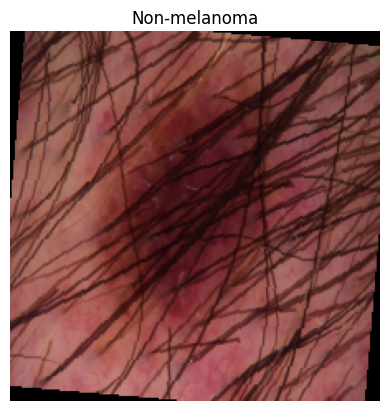

In [15]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

# Undo normalization for displaying
image = image.permute(1, 2, 0)
mean = torch.tensor([0.485, 0.456, 0.406])
std = torch.tensor([0.229, 0.224, 0.225])

image = image * std + mean
image = image.clamp(0, 1)

plt.imshow(image)
plt.title("Melanoma" if label.item() == 1 else "Non-melanoma")
plt.axis("off")
plt.show()

In [16]:
print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 23043
Validation dataset: 4903
Test dataset: 5180


## ResNet50 — DataLoaders

In [17]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Train batches: 721
Validation batches: 154
Test batches: 162
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


## ResNet50 Model

In [18]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

model.fc = nn.Linear(
    model.fc.in_features,
    2
)

model = model.to(device)

print("Fresh ResNet50 ready:", device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 211MB/s]


Fresh ResNet50 ready: cuda


In [19]:
class_counts = train_df_split["target"].value_counts().sort_index()

weights = (
    len(train_df_split)
    / (2 * class_counts)
).to_numpy()

class_weights_tensor = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Loss and optimizer ready.")

Loss and optimizer ready.


In [20]:
# Recalculate class weights cleanly
class_counts = train_df_split["target"].value_counts().sort_index()

total = class_counts.sum()
num_classes = 2

weights = total / (num_classes * class_counts)

print("Class counts:")
print(class_counts)

print("\nCalculated weights:")
print(weights)

# Convert to PyTorch tensor
class_weights_tensor = torch.tensor(
    weights.to_numpy(),
    dtype=torch.float32
).to(device)

print("\nTensor weights:")
print(class_weights_tensor)

# Weighted loss
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

Class counts:
target
0    22644
1      399
Name: count, dtype: int64

Calculated weights:
target
0     0.50881
1    28.87594
Name: count, dtype: float64

Tensor weights:
tensor([ 0.5088, 28.8759], device='cuda:0')


In [21]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = model(images)

print("Output shape:", outputs.shape)

loss = criterion(outputs, labels)

print("Test loss:", loss.item())

Output shape: torch.Size([32, 2])
Test loss: 0.7126754522323608


## ResNet50 Training

In [22]:

import os
import time
import torch

NUM_EPOCHS = 3
CHECKPOINT_EVERY = 50
SAVE_DIR = "/kaggle/working"
os.makedirs(SAVE_DIR, exist_ok=True)

# Mixed precision on CUDA
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

history = {
    "train_loss": [],
    "train_accuracy": []
}

print("Starting ResNet50 training with mixed precision...")
print("GPUs available:", torch.cuda.device_count())
print("Total batches per epoch:", len(train_loader))

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    print(f"\n========== EPOCH {epoch + 1}/{NUM_EPOCHS} ==========")

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % CHECKPOINT_EVERY == 0:
            elapsed = time.time() - start_time
            remaining = (
                elapsed / (batch_idx + 1)
                * (len(train_loader) - batch_idx - 1)
            )

            print(
                f"Batch {batch_idx + 1}/{len(train_loader)} | "
                f"Loss: {running_loss / total:.4f} | "
                f"Acc: {correct / total:.4f} | "
                f"Elapsed: {elapsed / 60:.1f} min | "
                f"ETA: {remaining / 60:.1f} min"
            )

        # Save resumable checkpoint, including mixed-precision scaler
        if (batch_idx + 1) % CHECKPOINT_EVERY == 0:
            checkpoint = {
                "epoch": epoch,
                "batch": batch_idx + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "history": history,
                "train_loss_so_far": running_loss / total,
                "train_accuracy_so_far": correct / total
            }
            torch.save(
                checkpoint,
                os.path.join(SAVE_DIR, "resnet50_latest_checkpoint.pth")
            )

    train_loss = running_loss / total
    train_accuracy = correct / total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    print(f"\nEpoch {epoch + 1} complete")
    print(f"Train loss: {train_loss:.4f}")
    print(f"Train accuracy: {train_accuracy:.4f}")

    # Save weights for this epoch
    torch.save(
        model.state_dict(),
        os.path.join(SAVE_DIR, f"resnet50_epoch_{epoch + 1}.pth")
    )

    # Save complete checkpoint at epoch boundary
    torch.save({
        "epoch": epoch,
        "batch": len(train_loader),
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history
    }, os.path.join(SAVE_DIR, "resnet50_latest_checkpoint.pth"))

    torch.save(
        history,
        os.path.join(SAVE_DIR, "resnet50_training_history.pth")
    )

    torch.save(
        model.state_dict(),
        os.path.join(SAVE_DIR, "resnet50_phase1.pth")
    )

    print("Saved epoch weights and checkpoint.")

    from IPython.display import FileLink, display
    
    display(FileLink(
        os.path.join(SAVE_DIR, f"resnet50_epoch_{epoch + 1}.pth")
    ))

print("\nTraining finished.")
print("Final history:", history)


Starting ResNet50 training with mixed precision...
GPUs available: 2
Total batches per epoch: 721

========== EPOCH 1/3 ==========
Batch 50/721 | Loss: 0.4965 | Acc: 0.9587 | Elapsed: 4.8 min | ETA: 64.1 min
Batch 100/721 | Loss: 0.4990 | Acc: 0.9309 | Elapsed: 9.6 min | ETA: 59.5 min
Batch 150/721 | Loss: 0.5230 | Acc: 0.9165 | Elapsed: 14.4 min | ETA: 54.8 min
Batch 200/721 | Loss: 0.5125 | Acc: 0.8883 | Elapsed: 19.4 min | ETA: 50.4 min
Batch 250/721 | Loss: 0.4998 | Acc: 0.8671 | Elapsed: 24.2 min | ETA: 45.6 min
Batch 300/721 | Loss: 0.5236 | Acc: 0.8681 | Elapsed: 28.9 min | ETA: 40.6 min
Batch 350/721 | Loss: 0.5249 | Acc: 0.8723 | Elapsed: 33.8 min | ETA: 35.8 min
Batch 400/721 | Loss: 0.5150 | Acc: 0.8812 | Elapsed: 38.7 min | ETA: 31.0 min
Batch 450/721 | Loss: 0.5058 | Acc: 0.8842 | Elapsed: 43.6 min | ETA: 26.3 min
Batch 500/721 | Loss: 0.4985 | Acc: 0.8879 | Elapsed: 48.5 min | ETA: 21.4 min
Batch 550/721 | Loss: 0.4911 | Acc: 0.8909 | Elapsed: 53.2 min | ETA: 16.6 min
Bat

/kaggle/working/resnet50_epoch_1.pth


========== EPOCH 2/3 ==========
Batch 50/721 | Loss: 0.3821 | Acc: 0.8438 | Elapsed: 4.8 min | ETA: 64.0 min
Batch 100/721 | Loss: 0.4062 | Acc: 0.8553 | Elapsed: 9.6 min | ETA: 59.5 min
Batch 150/721 | Loss: 0.4091 | Acc: 0.8627 | Elapsed: 14.4 min | ETA: 54.6 min
Batch 200/721 | Loss: 0.4067 | Acc: 0.8661 | Elapsed: 19.0 min | ETA: 49.4 min
Batch 250/721 | Loss: 0.4177 | Acc: 0.8649 | Elapsed: 23.8 min | ETA: 44.9 min
Batch 300/721 | Loss: 0.4163 | Acc: 0.8675 | Elapsed: 28.4 min | ETA: 39.8 min
Batch 350/721 | Loss: 0.4173 | Acc: 0.8705 | Elapsed: 33.2 min | ETA: 35.1 min
Batch 400/721 | Loss: 0.4282 | Acc: 0.8607 | Elapsed: 37.9 min | ETA: 30.4 min
Batch 450/721 | Loss: 0.4260 | Acc: 0.8561 | Elapsed: 42.7 min | ETA: 25.7 min
Batch 500/721 | Loss: 0.4269 | Acc: 0.8551 | Elapsed: 47.5 min | ETA: 21.0 min
Batch 550/721 | Loss: 0.4251 | Acc: 0.8544 | Elapsed: 52.4 min | ETA: 16.3 min
Batch 600/721 | Loss: 0.4277 | Acc: 0.8555 | Elapsed: 57.2 min | ETA: 11.5 min
Batch 650/721 | Loss: 

/kaggle/working/resnet50_epoch_2.pth


========== EPOCH 3/3 ==========
Batch 50/721 | Loss: 0.4015 | Acc: 0.8844 | Elapsed: 4.8 min | ETA: 63.9 min
Batch 100/721 | Loss: 0.3680 | Acc: 0.8747 | Elapsed: 9.5 min | ETA: 58.7 min
Batch 150/721 | Loss: 0.3762 | Acc: 0.8860 | Elapsed: 14.1 min | ETA: 53.9 min
Batch 200/721 | Loss: 0.4364 | Acc: 0.8839 | Elapsed: 19.0 min | ETA: 49.6 min
Batch 250/721 | Loss: 0.4397 | Acc: 0.8851 | Elapsed: 23.7 min | ETA: 44.7 min
Batch 300/721 | Loss: 0.4364 | Acc: 0.8790 | Elapsed: 28.3 min | ETA: 39.8 min
Batch 350/721 | Loss: 0.4326 | Acc: 0.8780 | Elapsed: 33.0 min | ETA: 35.0 min
Batch 400/721 | Loss: 0.4198 | Acc: 0.8850 | Elapsed: 37.7 min | ETA: 30.3 min
Batch 450/721 | Loss: 0.4132 | Acc: 0.8888 | Elapsed: 42.5 min | ETA: 25.6 min
Batch 500/721 | Loss: 0.4116 | Acc: 0.8898 | Elapsed: 47.3 min | ETA: 20.9 min
Batch 550/721 | Loss: 0.4134 | Acc: 0.8893 | Elapsed: 52.2 min | ETA: 16.2 min
Batch 600/721 | Loss: 0.4134 | Acc: 0.8907 | Elapsed: 57.0 min | ETA: 11.5 min
Batch 650/721 | Loss: 

/kaggle/working/resnet50_epoch_3.pth


Training finished.
Final history: {'train_loss': [0.47609399214729026, 0.42926463716788427, 0.40997097193525495], 'train_accuracy': [0.893677038580046, 0.8554441695959727, 0.8923317276396302]}


In [23]:
import os
import torch

checkpoint_path = "/kaggle/working/resnet50_latest_checkpoint.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
    print("Saved epoch:", checkpoint.get("epoch"))
    print("Saved batch:", checkpoint.get("batch"))
    print("Saved training loss:", checkpoint.get("train_loss_so_far"))

Checkpoint exists: True
Saved epoch: 2
Saved batch: 721
Saved training loss: None


In [24]:
import os

print("Current directory:", os.getcwd())

for filename in [
    "resnet50_phase1.pth",
    "resnet50_latest_checkpoint.pth",
    "resnet50_training_history.pth"
]:
    print(filename, "->", os.path.exists(filename))

Current directory: /kaggle/working
resnet50_phase1.pth -> True
resnet50_latest_checkpoint.pth -> True
resnet50_training_history.pth -> True


In [25]:

import os
import time
import torch

NUM_EPOCHS = 3
CHECKPOINT_EVERY = 50
SAVE_DIR = "/kaggle/working"
CHECKPOINT_PATH = os.path.join(SAVE_DIR, "resnet50_latest_checkpoint.pth")

os.makedirs(SAVE_DIR, exist_ok=True)

# Restore the latest saved checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scaler.load_state_dict(checkpoint["scaler_state_dict"])

history = checkpoint.get(
    "history",
    {"train_loss": [], "train_accuracy": []}
)

# Checkpoint uses zero-based epoch numbering
start_epoch = checkpoint["epoch"]
resume_batch = checkpoint["batch"]

print(f"Resuming epoch {start_epoch + 1}, after batch {resume_batch}")

for epoch in range(start_epoch, NUM_EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    # For the interrupted epoch, skip batches already processed.
    # The model/optimizer state is restored from that checkpoint.
    skip_batches = resume_batch if epoch == start_epoch else 0

    print(f"\n========== EPOCH {epoch + 1}/{NUM_EPOCHS} ==========")

    for batch_idx, (images, labels) in enumerate(train_loader):
        if batch_idx < skip_batches:
            continue

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        processed = batch_idx + 1
        if processed % CHECKPOINT_EVERY == 0:
            print(
                f"Epoch {epoch + 1}, Batch {processed}/{len(train_loader)}"
            )

            torch.save({
                "epoch": epoch,
                "batch": processed,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "history": history,
                "train_loss_so_far": running_loss / max(total, 1),
                "train_accuracy_so_far": correct / max(total, 1)
            }, CHECKPOINT_PATH)

    # For a resumed epoch, these metrics describe only the batches
    # processed since resuming, not the entire epoch.
    if total == 0:
        print("No batches processed in this epoch; skipping metrics.")
        continue

    train_loss = running_loss / total
    train_accuracy = correct / total

    print(f"Epoch {epoch + 1} resumed-section loss: {train_loss:.4f}")
    print(f"Epoch {epoch + 1} resumed-section accuracy: {train_accuracy:.4f}")

    # Save epoch weights
    torch.save(
        model.state_dict(),
        os.path.join(SAVE_DIR, f"resnet50_epoch_{epoch + 1}.pth")
    )

    # Save a checkpoint marking this epoch complete
    torch.save({
        "epoch": epoch + 1,
        "batch": 0,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history
    }, CHECKPOINT_PATH)

    resume_batch = 0

    print(f"Saved weights for epoch {epoch + 1}.")

print("\nResume training finished.")


Resuming epoch 3, after batch 721

========== EPOCH 3/3 ==========
No batches processed in this epoch; skipping metrics.

Resume training finished.


In [26]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torch

IMAGE_DIR = "/kaggle/input/competitions/siim-isic-melanoma-classification/jpeg/train"

class FixedMelanomaDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image_path = os.path.join(
            IMAGE_DIR, str(row["image_name"]) + ".jpg"
        )

        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        label = torch.tensor(int(row["target"]), dtype=torch.long)
        return image, label

fixed_val_dataset = FixedMelanomaDataset(
    val_loader.dataset.dataframe,
    transform=val_loader.dataset.transform
)

fixed_val_loader = DataLoader(
    fixed_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Validation images:", len(fixed_val_dataset))
print("First image loaded successfully:", fixed_val_dataset[0][0].shape)

Validation images: 4903
First image loaded successfully: torch.Size([3, 224, 224])


In [27]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
import numpy as np

model.eval()
all_labels, all_preds, all_probs = [], [], []

with torch.no_grad():
    for images, labels in fixed_val_loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        probs = torch.softmax(outputs.float(), dim=1)[:, 1]
        preds = (probs >= 0.5).long()

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

print("Validation Accuracy:", round(accuracy_score(all_labels, all_preds), 4))
print("Validation Precision:", round(precision_score(all_labels, all_preds, zero_division=0), 4))
print("Validation Recall:", round(recall_score(all_labels, all_preds, zero_division=0), 4))
print("Validation F1:", round(f1_score(all_labels, all_preds, zero_division=0), 4))
print("Validation ROC-AUC:", round(roc_auc_score(all_labels, all_probs), 4))
print("Confusion Matrix:\n", confusion_matrix(all_labels, all_preds))

Validation Accuracy: 0.8489
Validation Precision: 0.0628
Validation Recall: 0.6575
Validation F1: 0.1147
Validation ROC-AUC: 0.8628
Confusion Matrix:
 [[4114  716]
 [  25   48]]


In [28]:

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    average_precision_score
)

test_dataset = FixedMelanomaDataset(
    test_loader.dataset.dataframe,
    transform=test_loader.dataset.transform
)

test_eval_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

model.load_state_dict(torch.load(
    "/kaggle/working/resnet50_epoch_3.pth",
    map_location=device,
    weights_only=True
))
model.eval()

y_true, y_prob = [], []

with torch.no_grad():
    for images, labels in test_eval_loader:
        images = images.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        probabilities = torch.softmax(outputs.float(), dim=1)[:, 1]
        y_true.extend(labels.numpy())
        y_prob.extend(probabilities.cpu().numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

print("Test images:", len(y_true))
print("Threshold: 0.50")
print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4%}")
print(f"Test precision: {precision_score(y_true, y_pred, zero_division=0):.4%}")
print(f"Test recall: {recall_score(y_true, y_pred, zero_division=0):.4%}")
print(f"Test specificity: {tn / (tn + fp):.4%}")
print(f"Test F1-score: {f1_score(y_true, y_pred, zero_division=0):.4%}")
print(f"Test ROC-AUC: {roc_auc_score(y_true, y_prob):.4f}")
print(f"Test PR-AUC: {average_precision_score(y_true, y_prob):.4f}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred, labels=[0, 1]))


Test images: 5180
Threshold: 0.50
Test accuracy: 85.1351%
Test precision: 9.5823%
Test recall: 69.6429%
Test specificity: 85.4775%
Test F1-score: 16.8467%
Test ROC-AUC: 0.8733
Test PR-AUC: 0.1417
TN=4332, FP=736, FN=34, TP=78
Confusion matrix:
 [[4332  736]
 [  34   78]]
